# Etapa 7: comparação entre os modelos

Entrada: `report/results/multiseed.csv`, gerado por `scripts/multiseed.py`, e a base de sempre para o experimento-ponte.

Os notebooks 03 a 06 ajustam cada modelo com uma única seed (42). Uma seed só não diz se 1 ponto de diferença é real ou sorte do sorteio. Por isso `scripts/multiseed.py` repete a busca de hiperparâmetros e a avaliação de todos os modelos com 10 seeds. Cada seed muda o split de treino e teste e as partes da validação cruzada. Este notebook compara os modelos com média e desvio dessas 10 rodadas, sempre no cenário escolhido: descritores + SMILES, split agrupado.

Depois, o **experimento-ponte** separa as duas coisas que a Random Forest acrescenta à árvore de decisão: o sorteio de atributos em cada nó (que transforma a árvore numa Random Tree) e a média de muitas árvores treinadas em amostras bootstrap (bagging).

O código fica em `src/comparison.py`.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from src import comparison, modeling, plots
from src.config import FINAL_CSV

plots.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

final = pd.read_csv(FINAL_CSV)
dados = modeling.prepare(final)
print("X:", dados.X.shape, "| classes:", dados.y.nunique())

MULTISEED = ROOT / "report" / "results" / "multiseed.csv"
resultados = comparison.load_multiseed(MULTISEED)

X: (27476, 17) | classes: 4


## 1. Todos os modelos, 10 seeds

"Padrão" é o modelo com os hiperparâmetros de fábrica do scikit-learn, como no notebook 03; "ajustado" passou pela busca em grade dos notebooks 04 a 06. O tempo de treino é o de um ajuste com os hiperparâmetros escolhidos, sem a busca, numa máquina de 12 núcleos.

In [2]:
tabela = comparison.multiseed_table(resultados)
tabela

,acurácia (%),desvio (pontos),F1 macro (%),tempo de treino (s),seeds
modelo,,,,,
Classe majoritária,29.30,0.00,11.30,0.01,10
Árvore de decisão,89.41,0.42,89.27,0.23,10
Random Tree (padrão Weka),87.61,1.07,87.51,0.11,10
Random Tree (ajustada),89.04,0.67,88.87,0.21,10
Bagging de árvores,93.82,0.35,93.75,5.65,10
Random Forest (padrão),95.17,0.27,95.10,2.27,10
Random Forest (ajustada),95.26,0.29,95.18,1.96,10
Gradient boosting (padrão),94.79,0.26,94.73,7.40,10
Gradient boosting (ajustado),96.64,0.26,96.56,39.29,10


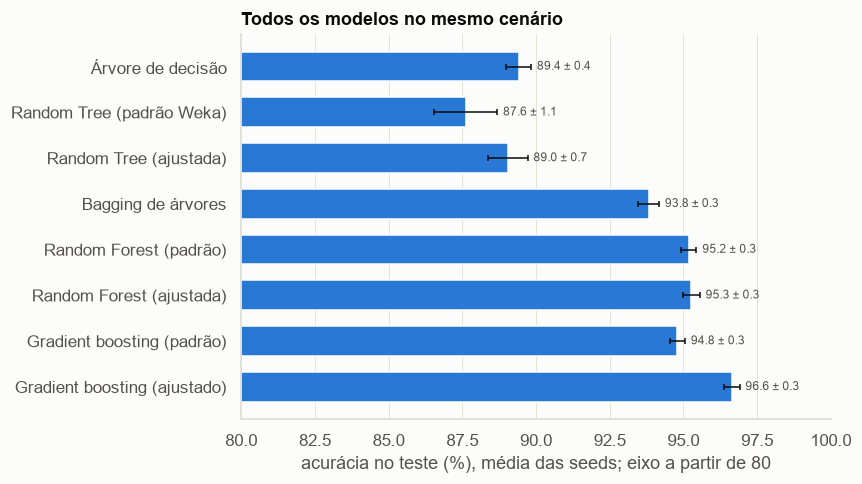

In [3]:
plots.models_summary(tabela.drop(index="Classe majoritária"), low=80)

Os modelos se separam em três grupos, e a distância entre os grupos é muito maior que o desvio dentro de cada um:

- **Árvores únicas, de 87,6% a 89,4%.** A árvore de decisão é a melhor delas. A Random Tree ajustada fica 0,4 ponto abaixo, e a do padrão do Weka, 1,8 ponto abaixo. A Random Tree também tem o maior desvio entre seeds (1,1 ponto no padrão do Weka, contra 0,4 da árvore).
- **Bagging, 93,8%.** 300 árvores de decisão em amostras bootstrap, sem sorteio de atributos.
- **Random Forest e gradient boosting, de 94,8% a 96,6%.** O gradient boosting ajustado é o melhor modelo: 96,6 ± 0,3%. A Random Forest ajustada empata com a padrão (95,3% e 95,2%); o ajuste do boosting, ao contrário, rende 1,8 ponto.

Os tempos de treino servem só como ordem de grandeza: foram medidos enquanto outros processos usavam a mesma máquina. Mesmo assim, a escala é clara: uma árvore treina em décimos de segundo, e os conjuntos, em segundos ou dezenas de segundos.

## 2. Ganho sobre a árvore de decisão

Como todos os modelos de uma seed usam o mesmo split, a diferença para a árvore pode ser medida seed a seed. Isso tira a variação que vem do sorteio do split e deixa só a diferença entre os modelos.

In [4]:
comparison.gain_over_tree(resultados)

,ganho médio (pontos),desvio,seeds com ganho
modelo,,,
Classe majoritária,-60.11,0.42,0
Random Tree (padrão Weka),-1.80,1.09,0
Random Tree (ajustada),-0.37,0.66,3
Bagging de árvores,4.41,0.41,10
Random Forest (padrão),5.76,0.43,10
Random Forest (ajustada),5.85,0.44,10
Gradient boosting (padrão),5.38,0.40,10
Gradient boosting (ajustado),7.23,0.40,10


Todos os conjuntos de árvores superam a árvore de decisão nas 10 seeds, sem exceção, por 4,4 a 7,2 pontos. A Random Tree, ao contrário, perde para a árvore: a do padrão do Weka em todas as 10 seeds (−1,8 ponto), e a ajustada em 7 das 10 (−0,4 ponto). Medida seed a seed, a diferença tem desvio de 0,4 ponto, então os ganhos dos conjuntos estão bem acima do ruído.

## 3. Random Tree contra árvore de decisão nos 6 cenários

A mesma comparação do notebook 04, agora com a média de 10 seeds.

In [5]:
comparison.rt_vs_dt(MULTISEED)

modelo                          Random Tree  Árvore de decisão  diferença (pontos)  seeds com RT melhor
features             split                                                                             
descritores          agrupada         75.15              77.15               -2.00                    0
                     aleatória        80.47              81.21               -0.74                    1
descritores + SMILES agrupada         89.04              89.41               -0.37                    3
                     aleatória        90.47              90.76               -0.29                    2
só SMILES            agrupada         87.43              87.60               -0.17                    4
                     aleatória        88.90              88.88                0.02                    6

Com 10 seeds, a conclusão do notebook 04 se confirma: a Random Tree ajustada fica abaixo da árvore de decisão em 5 dos 6 cenários. A perda é maior quando há menos atributos e o split é agrupado: −2,0 pontos com os 5 descritores. Com 5 atributos, a busca da seed 42 escolhe K = 3, e cada nó perde de vista 2 dos 5 atributos; com 17, K = 12 deixa de fora uma parcela menor. O único empate (+0,02 ponto, 6 de 10 seeds) acontece com o conjunto "só SMILES" e split aleatório.

## 4. Experimento-ponte: de onde vem o ganho da Random Forest

Quatro modelos, todos com a mesma árvore base (sem poda, folha mínima de 1 linha), no cenário escolhido e com a seed 42. Só mudam duas coisas:

| | 1 árvore | 300 árvores (bootstrap) |
|---|---|---|
| **sem sorteio de atributos** | árvore de decisão | bagging |
| **com sorteio de atributos (K = 4)** | Random Tree | Random Forest |

K = 4 é o `sqrt(17)`, o padrão da Random Forest, perto do K = 5 do Weka. As árvores únicas aparecem como a média de 10 sementes, porque a Random Tree varia de uma semente para outra (notebook 04).

,sorteio de atributos,árvores,acurácia teste,desvio entre sementes
0,sem sorteio,1 árvore,0.8851,0.0016
1,com sorteio,1 árvore,0.8664,0.0087
2,sem sorteio,300 árvores,0.9390,NaN
3,com sorteio,300 árvores,0.9521,NaN


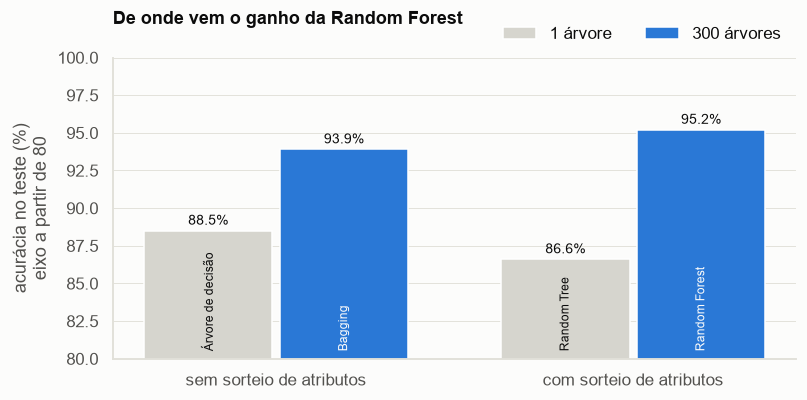

árvores,1 árvore,300 árvores
sorteio de atributos,,
com sorteio,86.6,95.2
sem sorteio,88.5,93.9


In [6]:
ponte = comparison.bridge(dados)
display(ponte)
matriz_ponte = comparison.bridge_matrix(ponte)
plots.bridge(matriz_ponte)
matriz_ponte

O desenho separa as duas fontes de ganho da Random Forest. Partindo da árvore de decisão sem poda (88,5%; um pouco abaixo dos 89,7% da árvore ajustada no notebook 03, que usa entropia):

- **Média de 300 árvores sem sorteio (bagging): +5,4 pontos** (88,5% → 93,9%).
- **Sorteio de atributos sobre o bagging: +1,3 ponto** (93,9% → 95,2%).
- **Sorteio de atributos numa árvore só: −1,9 ponto** (88,5% → 86,6%), e com desvio entre sementes 5 vezes maior (0,87 contra 0,16 ponto).

Cerca de 80% do ganho da Random Forest vem da média, não do sorteio. E o sorteio tem efeito oposto nos dois casos: atrapalha uma árvore sozinha e ajuda um conjunto. Com uma árvore só, esconder o melhor atributo de um nó só piora o corte. Num conjunto, o sorteio deixa as árvores mais diferentes entre si: elas erram em moléculas diferentes, e a média cancela mais erros. No bagging, as 300 árvores veem os mesmos 17 atributos e tendem a fazer os mesmos primeiros cortes (TPSA, `n_aromatic`), então erram juntas com mais frequência.

**É por isso que a Random Tree sozinha perde para a árvore de decisão e mesmo assim é a peça da Random Forest.**

## 5. Bagging e Random Forest por número de árvores

A mesma comparação, agora com o número de árvores variando de 1 a 300, num fold de validação agrupado tirado do treino.

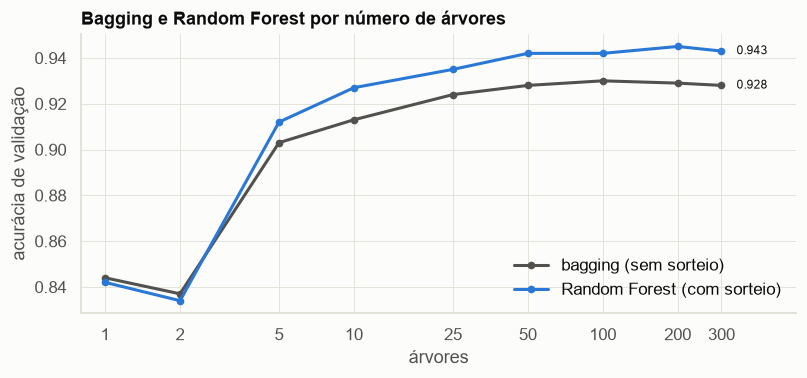

árvores,1,2,5,10,25,50,100,200,300
bagging (sem sorteio),0.844,0.837,0.903,0.913,0.924,0.928,0.930,0.929,0.928
Random Forest (com sorteio),0.842,0.834,0.912,0.927,0.935,0.942,0.942,0.945,0.943


In [7]:
curva = comparison.bridge_curve(dados)
plots.bridge_curve(curva)
curva.T

A curva mostra o mesmo efeito com o número de árvores variando. Com 1 e 2 árvores, bagging e Random Forest empatam (0,84). As duas aqui são árvores em amostras bootstrap, mais fracas que a árvore de decisão no treino completo. As curvas se separam a partir de 5 árvores. O bagging para de melhorar por volta de 50 árvores (0,928), enquanto a Random Forest ainda sobe e fica entre 0,942 e 0,945. Árvores mais parecidas entre si param de acrescentar informação mais cedo.

## 6. F1 por classe

Média das 10 seeds, em %.

In [8]:
comparison.per_class_f1(resultados)

,EGFR,BACE1,DRD2,HDAC1
modelo,,,,
Árvore de decisão,89.2,90.9,90.4,86.6
Random Tree (padrão Weka),86.9,89.6,88.8,84.6
Random Tree (ajustada),88.8,90.7,90.2,85.9
Bagging de árvores,93.6,94.8,94.3,92.2
Random Forest (padrão),94.8,96.2,95.7,93.7
Random Forest (ajustada),94.8,96.2,95.7,94.0
Gradient boosting (padrão),94.3,96.0,95.7,92.9
Gradient boosting (ajustado),96.3,97.5,97.0,95.4


A ordem das classes é a mesma em todos os modelos: BACE1 e DRD2 são as mais fáceis e HDAC1 a mais difícil. Os conjuntos de árvores melhoram todas as classes, e HDAC1 é a que mais ganha: de 86,6% de F1 na árvore para 95,4% no gradient boosting ajustado (+8,8 pontos, contra +6,6 em BACE1). A confusão HDAC1 ↔ EGFR diminui, mas continua sendo o principal par de erros em todos os modelos (notebooks 04 a 06).

## 7. Acurácia, estabilidade e interpretabilidade

| Modelo | Acurácia (10 seeds) | Desvio | Regras legíveis | Confiança útil |
|---|---|---|---|---|
| Árvore de decisão | 89,4% | 0,4 | sim | não: 100% em quase tudo |
| Random Tree (ajustada) | 89,0% | 0,7 | sim, mas mudam com a semente | não |
| Random Forest | 95,2% | 0,3 | não | sim: 91% dos erros abaixo de 70% de confiança |
| Gradient boosting (ajustado) | 96,6% | 0,3 | não | em parte: 20% dos erros acima de 99,9% |

A Random Tree não ocupa nenhum lugar útil nessa tabela. Ela é menos precisa e menos estável que a árvore de decisão, e as regras dela mudam de uma semente para outra, então nem a legibilidade compensa. Entre os conjuntos, o gradient boosting acerta mais. A Random Forest acerta 1,4 ponto a menos, mas não precisa de ajuste e diz quando está em dúvida.

## 8. Conclusões

1. **Gradient boosting ajustado é o modelo mais preciso:** 96,6 ± 0,3%, 7,2 pontos acima da árvore de decisão, nas 10 seeds.
2. **Random Forest é o melhor custo-benefício:** 95,2% com os hiperparâmetros padrão, sem busca, e com confiança que separa acertos de erros.
3. **A Random Tree sozinha perde para a árvore de decisão:** −0,4 ponto ajustada e −1,8 ponto no padrão do Weka. Ela também varia mais com a semente. O sorteio de atributos esconde o melhor corte de cada nó, e uma árvore só não tem como compensar isso.
4. **Mesmo assim, ela é a peça que faz a Random Forest funcionar.** O experimento-ponte mostra que a média de muitas árvores (bagging) traz cerca de 80% do ganho. O sorteio de atributos traz o resto, mas só dentro de um conjunto: ele torna as árvores diferentes entre si, e a média cancela mais erros.
5. **A árvore de decisão continua sendo a única com regras legíveis.** Os 4 a 7 pontos de acurácia dos conjuntos são o preço dessa legibilidade.
6. **Nenhum modelo resolve a confusão HDAC1 ↔ EGFR.** Ela vem da representação: as contagens de caracteres do SMILES não enxergam como os átomos estão ligados.